# Can the NGC4567_8 velocity field separate NGC4567 and NGC4568?
**2026-11-10 · MAUVE exploratory map-level assignment**

Fit two projected rotating disks to the sides facing away from the companion, independently for the stars and Hα. Compare each measured centroid with both predictions at its sky position. Retain assignments that survive a change in the training regions and agree between tracers. Keep single-tracer evidence, disagreements, and ambiguous bins visible.

Kaneko et al. identify a molecular collision front in this pair and report an overlap in projected position and velocity. A single stellar LOSVD or Hα centroid may mix both galaxies or trace disturbed gas. The resulting map identifies which disk a measured velocity is more consistent with, and cannot recover each galaxy's flux in a blended spectrum. [Kaneko et al. 2018](https://arxiv.org/abs/1805.11630) · [Kaneko et al. 2023](https://academic.oup.com/pasj/article/75/3/646/7133996)

In [1]:
%matplotlib inline

from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.wcs import WCS
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.lines import Line2D
from scipy.optimize import least_squares

ROOT = Path.cwd()
CUBE = "NGC4567_8"
GALAXIES = ["NGC4567", "NGC4568"]
PRODUCT = ROOT / "v3tk_v7.6.8" / CUBE
SEED_CUTS = [0.60, 0.45, 0.70]  # axial fraction from the 4567 nucleus to the 4568 nucleus
N_FOLDS = 6
CORE_EXCLUSION = 3.0  # arcsec
MIN_HA_SN = 5.0
MAX_V_ERROR = {"Stars": 20.0, "Hα": 15.0}  # km/s
MIN_SCORE_GAP = 1.0
MAX_RESIDUAL = 2.0
SCATTER_FLOOR = 5.0  # km/s

def read_maps(suffix, names):
    with fits.open(PRODUCT / f"{CUBE}_{suffix}.fits", memmap=True) as hdus:
        maps = {name: hdus[name].data.astype(float) for name in names}
        grids = {name: WCS(hdus[name].header).celestial for name in names}
    return maps, grids

kin, wk = read_maps("kin_maps", ["V", "FORM_ERR_V"])
gas, wg = read_maps("gas_bin_maps_further", [
    "BIN_ID", "V_STARS2", "HA6562_VEL", "HA6562_VEL_ERR", "HA6562_FLUX", "HA6562_FLUX_ERR"
])
spatial, ws = read_maps("spatial_binning_maps_further", ["BINID", "FLUX"])
wcs = wk["V"]
ny, nx = kin["V"].shape
grid_x, grid_y = [0, nx - 1, 0, nx - 1, nx / 2], [0, 0, ny - 1, ny - 1, ny / 2]
sky_check = wcs.pixel_to_world(grid_x, grid_y)
for grids, maps in [(wk, kin), (wg, gas), (ws, spatial)]:
    for name, grid in grids.items():
        assert maps[name].shape == (ny, nx), name
        assert np.max(sky_check.separation(grid.pixel_to_world(grid_x, grid_y)).arcsec) < 1e-4, name
np.testing.assert_array_equal(spatial["BINID"], gas["BIN_ID"])
np.testing.assert_array_equal(kin["V"], gas["V_STARS2"])

cube_row = pd.read_csv(ROOT / "cube_centers_v3tk.csv").set_index("ID").loc[CUBE]
assert (cube_row.ny, cube_row.nx) == (ny, nx)
catalog = pd.read_csv(ROOT / "simbad_object_crosswalk.csv").set_index("component").loc[GALAXIES]
centres = SkyCoord(catalog.ra_deg.to_numpy(), catalog.dec_deg.to_numpy(), unit="deg")
cx, cy = wcs.world_to_pixel(centres)
assert np.all((0 <= cx) & (cx < nx) & (0 <= cy) & (cy < ny))
inclination = pd.read_csv(ROOT / "MAUVE_Inclination.dat", sep=r"\s+", comment="#",
                         header=None, names=["galaxy", "inclination"]).set_index("galaxy").loc[GALAXIES, "inclination"]
colours = {}
for line in (ROOT / "MAUVE_galaxy_colors.dat").read_text().splitlines():
    fields = line.split()
    if len(fields) >= 4 and fields[1] in GALAXIES:
        colours[fields[1]] = fields[3]
assert set(colours) == set(GALAXIES)

footprint = np.isfinite(gas["BIN_ID"])
py, px = np.nonzero(footprint)
ids, first, inverse, counts = np.unique(gas["BIN_ID"][footprint], return_index=True,
                                       return_inverse=True, return_counts=True)
assert np.all((ids >= 0) & (ids == np.floor(ids)))
bx = np.bincount(inverse, weights=px) / counts
by = np.bincount(inverse, weights=py) / counts
bin_icrs = wcs.pixel_to_world(bx, by).icrs
bin_sky = SkyCoord(ra=bin_icrs.ra, dec=bin_icrs.dec, frame="icrs")

def per_bin(image):
    values = image[footprint]
    np.testing.assert_array_equal(values, values[first][inverse])
    return values[first]

star = per_bin(kin["V"])
star_err = per_bin(kin["FORM_ERR_V"])
ha = per_bin(gas["HA6562_VEL"])
ha_err = per_bin(gas["HA6562_VEL_ERR"])
ha_flux = per_bin(gas["HA6562_FLUX"])
ha_flux_err = per_bin(gas["HA6562_FLUX_ERR"])
ha_sn = np.divide(ha_flux, ha_flux_err, out=np.full(len(ids), np.nan), where=ha_flux_err > 0)
tracers = {
    "Stars": (star, star_err, np.ones(len(ids), dtype=bool)),
    "Hα": (ha, ha_err, ha_sn >= MIN_HA_SN),
}
offsets = []
for centre in centres:
    east, north = centre.spherical_offsets_to(bin_sky)
    offsets.append((east.arcsec, north.arcsec))
east12, north12 = centres[0].spherical_offsets_to(centres[1])
axis = np.array([east12.arcsec, north12.arcsec])
separation = np.linalg.norm(axis)
east, north = offsets[0]
fraction = (axis[0] * east + axis[1] * north) / separation**2
assert np.isfinite(fraction).all()
distance = np.array([np.hypot(e, n) for e, n in offsets])
print(f"{len(ids):,} distinct bins cover {footprint.sum():,} spaxels on a {nx} × {ny} grid.")
print(f"Cube centre CSV (x, y) = ({cube_row.center_x}, {cube_row.center_y}); nucleus separation = {separation:.1f} arcsec.")
display(catalog[["ra_deg", "dec_deg", "coordinate_bibcode"]].assign(x=cx, y=cy, inclination_deg=inclination))

No event loop hook running.
31,846 distinct bins cover 510,118 spaxels on a 971 × 1059 grid.
Cube centre CSV (x, y) = (486, 530); nucleus separation = 73.5 arcsec.


Matplotlib is building the font cache; this may take a moment.


,ra_deg,dec_deg,coordinate_bibcode,x,y,inclination_deg
component,,,,,,
NGC4567,189.136242,11.257977,2020yCat.1350....0G,520.638848,782.511158,49
NGC4568,189.142883,11.238631,2006AJ....131.1163S,403.365187,434.286432,70


The centre CSV supplies the combined cube dimensions and midpoint. It has one row for the pair. The component positions come from the local SIMBAD crosswalk and are converted to zero-based pixels through the FITS WCS. Stellar velocities come from `kin_maps[V]` and match `V_STARS2` in the gas product; Hα comes from `HA6562_VEL` in the **BIN** product. Both maps are used in their native relative velocity frame, with a free intercept for each galaxy and tracer. The fit uses one observation at each bin's mean spaxel coordinate. Display pixels inherit the parent bin's result.

## Train and check the disk predictions

Fix each inclination to the local MAUVE value. Let (x') and (y') be the major- and minor-axis offsets for position angle PA (east of north, toward the receding side) and (R^2=x'^2+(y'/cos i)^2). Fit
[
v(x',y')=v_0+Arac{x'}{sqrt{R^2+R_t^2}}.
]
Here (A) is the asymptotic **projected** amplitude, (R_t) is the turnover scale, and (v_0) is the intercept in the map's frame. Use robust loss and equal bin weights. Reject poor formal velocity errors and require Hα flux/error ≥ 5. The fiducial seeds lie at axial fraction (t<0.40) for NGC4567 and (t>0.60) for NGC4568, where (t=0,1) at the nuclei. The wider and narrower seed variants probe overlap contamination and extrapolation. The inner 3 arcsec of each nucleus are excluded from training.

Hold out spatial groups defined by six sky sectors around each nucleus. Use their out-of-fold residuals to estimate a prediction scale. The validation samples the seed region and provides a diagnostic of model adequacy there. The interface itself has no known labels.

In [2]:
def disk(params, offset, inc):
    v0, amplitude, pa, turnover = params
    east, north = offset
    x = east * np.sin(pa) + north * np.cos(pa)
    y = east * np.cos(pa) - north * np.sin(pa)
    radius = np.hypot(x, y / np.cos(np.deg2rad(inc)))
    return v0 + amplitude * x / np.hypot(radius, turnover), radius

def fit_disk(offset, v, inc, use):
    local = tuple(coord[use] for coord in offset)
    target = v[use]
    assert len(target) >= 100

    def residual(params):
        return disk(params, local, inc)[0] - target

    solutions = [
        least_squares(residual, [np.median(target), 130, angle, 20],
                      bounds=([-300, 0, -4*np.pi, 1], [300, 400, 4*np.pi, 150]),
                      loss="soft_l1", f_scale=10, x_scale=[50, 100, 1, 30])
        for angle in np.linspace(0, 2*np.pi, 4, endpoint=False)
    ]
    solution = min((fit for fit in solutions if fit.success), key=lambda fit: fit.cost)
    return solution.x

def seed_region(index, cut):
    side = fraction < 1 - cut if index == 0 else fraction > cut
    return side & (distance[index] > CORE_EXCLUSION)

def robust_scale(residual):
    # Absolute held-out residual includes any systematic prediction offset.
    return max(SCATTER_FLOOR, np.percentile(np.abs(residual), 68.27))

results = {}
rows = []
for tracer, (vel, error, sn_ok) in tracers.items():
    usable = np.isfinite(vel) & np.isfinite(error) & (error > 0) & (error <= MAX_V_ERROR[tracer]) & sn_ok
    for cut in SEED_CUTS:
        models = []
        for index, (galaxy, inc, offset) in enumerate(zip(GALAXIES, inclination, offsets)):
            seed = usable & seed_region(index, cut)
            east, north = offset
            sector = np.floor((np.arctan2(east, north) + np.pi) * N_FOLDS / (2*np.pi)).astype(int) % N_FOLDS
            held_out = np.full(len(ids), np.nan)
            for group in np.unique(sector[seed]):
                test = seed & (sector == group)
                params = fit_disk(offset, vel, inc, seed & ~test)
                pred, _ = disk(params, offset, inc)
                held_out[test] = vel[test] - pred[test]
            assert np.isfinite(held_out[seed]).all()
            params = fit_disk(offset, vel, inc, seed)
            predicted, radius = disk(params, offset, inc)
            scale = robust_scale(held_out[seed])
            supported = radius <= np.quantile(radius[seed], 0.995)
            models.append((predicted, scale, supported))
            rows.append(dict(tracer=tracer, seed_cut=cut, galaxy=galaxy, bins=seed.sum(),
                             v0=params[0], amplitude=params[1], pa_deg=np.rad2deg(params[2]) % 360,
                             turnover_arcsec=params[3], heldout_scale=scale,
                             heldout_abs_p90=np.percentile(np.abs(held_out[seed]), 90)))
        results[tracer, cut] = (usable, models)

fit_summary = pd.DataFrame(rows)
with pd.option_context("display.max_columns", None):
    display(fit_summary.round(2))

,tracer,seed_cut,galaxy,bins,v0,amplitude,pa_deg,turnover_arcsec,heldout_scale,heldout_abs_p90
0,Stars,0.60,NGC4567,11455,47.53,102.90,91.59,22.99,7.87,13.05
1,Stars,0.60,NGC4568,16721,16.03,137.71,27.86,9.80,8.09,13.58
2,Stars,0.45,NGC4567,13228,47.95,109.25,93.32,25.84,8.86,14.90
3,Stars,0.45,NGC4568,18647,16.69,139.24,27.40,10.24,8.32,14.11
4,Stars,0.70,NGC4567,10486,47.35,100.37,91.24,21.83,7.74,12.60
5,Stars,0.70,NGC4568,15375,15.50,136.75,28.20,9.56,8.10,13.32
6,Hα,0.60,NGC4567,11469,47.37,92.03,91.53,11.27,11.70,21.73
7,Hα,0.60,NGC4568,16722,13.65,143.24,28.25,7.31,10.81,18.49
8,Hα,0.45,NGC4567,13242,48.20,103.01,93.85,16.98,14.86,27.51
9,Hα,0.45,NGC4568,18648,14.60,145.34,27.89,7.89,11.26,19.28


## Assign only when the predictions are distinguishable

For each tracer and seed choice, the score is the absolute residual divided by the larger of the bin's formal velocity error and the held-out residual scale for that disk. The preferred disk must lie within its fitted radial range (99.5th percentile of seed radii), have a score ≤ 2, beat the competitor by ≥ 1, and differ in predicted velocity from the competitor by at least the quadrature sum of the two scales. These are exploratory screening thresholds. The scores are descriptive and have no probability calibration. A competitor prediction outside its radial support is still used in the comparison, so the plots explicitly identify which assignments use such a comparison. Radius checks constrain radial extrapolation only.

A tracer is stable if it returns the same positive label for all three seed choices. The strict combined map requires both stable tracers to agree. The detailed map preserves the single-tracer cases and stable-tracer conflicts.

In [3]:
def classify(vel, error, usable, models):
    prediction = np.array([model[0] for model in models])
    scale = np.maximum(error, np.array([model[1] for model in models])[:, None])
    supported = np.array([model[2] for model in models])
    scores = np.abs(vel - prediction) / scale
    winner = np.argmin(scores, axis=0)
    cols = np.arange(len(ids))
    best, second = scores[winner, cols], scores[1-winner, cols]
    separated = abs(prediction[0] - prediction[1]) >= np.hypot(*scale)
    accepted = usable & supported[winner, cols] & separated & (best <= MAX_RESIDUAL) & (second - best >= MIN_SCORE_GAP)
    return np.where(accepted, winner + 1, np.where(usable, 0, -1))

labels = {}
stable = {}
for tracer, (vel, error, _) in tracers.items():
    labels[tracer] = np.array([classify(vel, error, *results[tracer, cut]) for cut in SEED_CUTS])
    nominal = labels[tracer][0]
    stable[tracer] = np.where(np.all(labels[tracer] == nominal, axis=0), nominal, 0)

s, g = stable["Stars"], stable["Hα"]
consensus = np.where((s > 0) & (s == g), s, np.where((s < 0) & (g < 0), -1, 0))
detail = consensus.copy()
detail[(s > 0) & (g <= 0)] = 2 + s[(s > 0) & (g <= 0)]
detail[(g > 0) & (s <= 0)] = 4 + g[(g > 0) & (s <= 0)]
detail[(s > 0) & (g > 0) & (s != g)] = 7
nearest = np.argmin(distance, axis=0) + 1
both_radial = np.logical_and.reduce([
    model[2] for _, models in results.values() for model in models
])
assignment_summary = pd.DataFrame([
    {"map": name, "NGC4567 bins": (a == 1).sum(), "NGC4568 bins": (a == 2).sum(),
     "ambiguous bins": (a == 0).sum(), "no usable bins": (a < 0).sum(),
     "NGC4567 spaxels": counts[a == 1].sum(), "NGC4568 spaxels": counts[a == 2].sum(),
     "ambiguous spaxels": counts[a == 0].sum(), "no usable spaxels": counts[a < 0].sum()}
    for name, a in [("Nearest nucleus", nearest), ("Stars fiducial", labels["Stars"][0]),
                    ("Hα fiducial", labels["Hα"][0]), ("Stars stable", s),
                    ("Hα stable", g), ("Both stable and agree", consensus),
                    ("Both stable, agree, both disks in radial range",
                     np.where((consensus > 0) & ~both_radial, 0, consensus))]
])
with pd.option_context("display.max_columns", None):
    display(assignment_summary)
for i, name in enumerate(GALAXIES, start=1):
    chosen = consensus == i
    print(f"{name}: {np.sum(chosen & (nearest != i)):,} consensus bins differ from the nearest-nucleus baseline.")
print(f"Stable tracers disagree in {(detail == 7).sum():,} bins.")
interface = (fraction >= 0.40) & (fraction <= 0.60)
print(f"In the central axial strip (0.40 ≤ t ≤ 0.60): {(interface & (consensus > 0)).sum():,} / "
      f"{interface.sum():,} bins have strict agreement. Of these, "
      f"{(interface & (consensus > 0) & both_radial).sum():,} also have both disks in radial range.")
assert np.array_equal(consensus > 0, (s > 0) & (s == g))
assert counts.sum() == footprint.sum()

NGC4567: 4 consensus bins differ from the nearest-nucleus baseline.
NGC4568: 102 consensus bins differ from the nearest-nucleus baseline.
Stable tracers disagree in 10 bins.
In the central axial strip (0.40 ≤ t ≤ 0.60): 463 / 2,457 bins have strict agreement. Of these, 463 also have both disks in radial range.


,map,NGC4567 bins,NGC4568 bins,ambiguous bins,no usable bins,NGC4567 spaxels,NGC4568 spaxels,ambiguous spaxels,no usable spaxels
0,Nearest nucleus,13187,18659,0,0,262861,247257,0,0
1,Stars fiducial,7001,15281,9543,21,132926,183664,193047,481
2,Hα fiducial,6340,14791,10709,6,121548,175162,208156,5252
3,Stars stable,6214,14401,11210,21,120077,170084,219476,481
4,Hα stable,5538,13103,13199,6,108049,152501,244316,5252
5,Both stable and agree,5032,12457,14357,0,101638,145991,262489,0
6,"Both stable, agree, both disks in radial range",60,858,30928,0,803,6693,502622,0


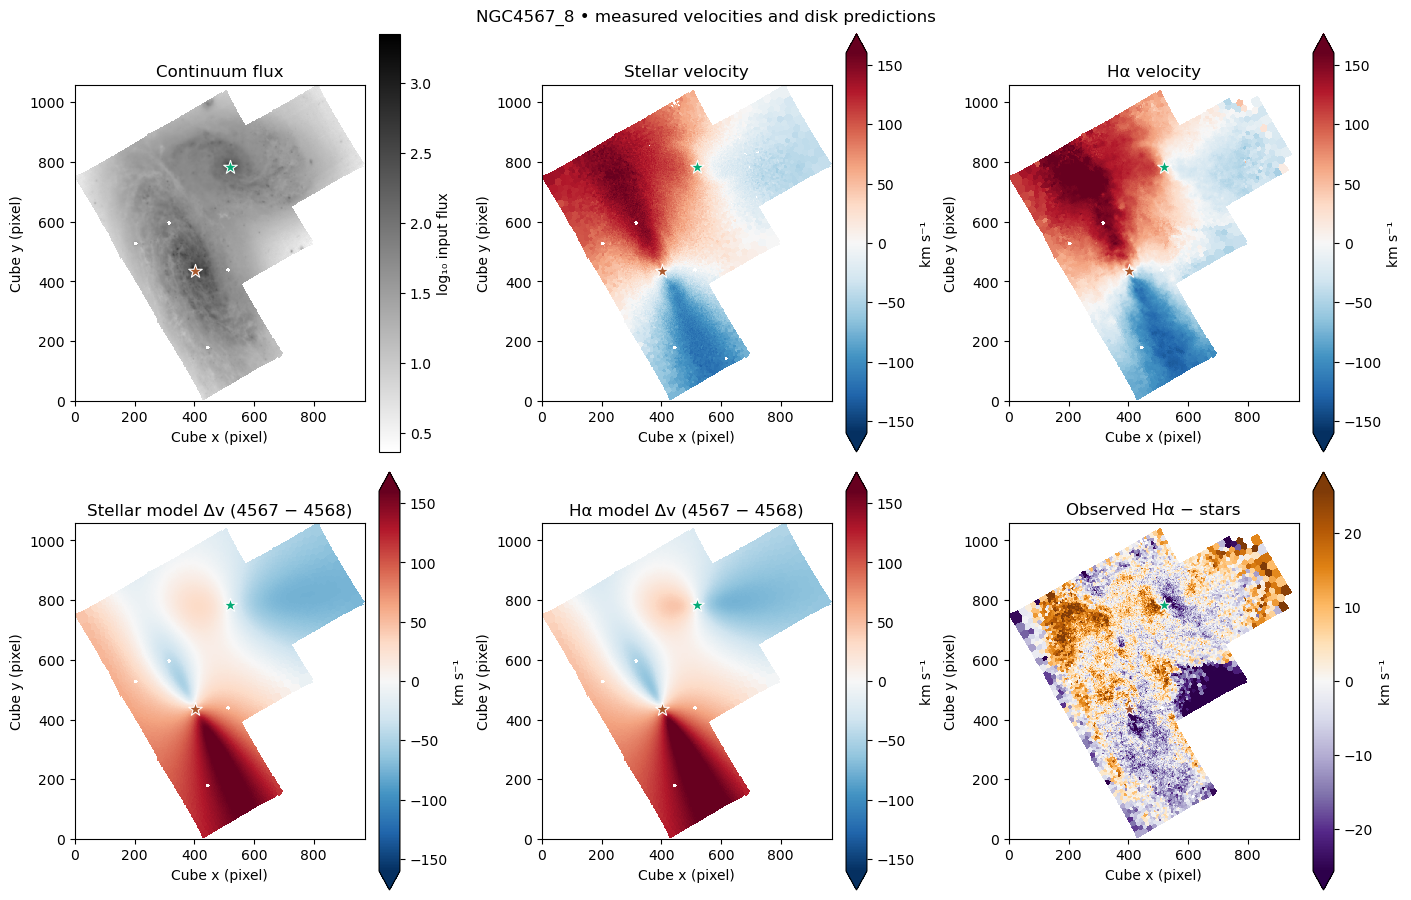

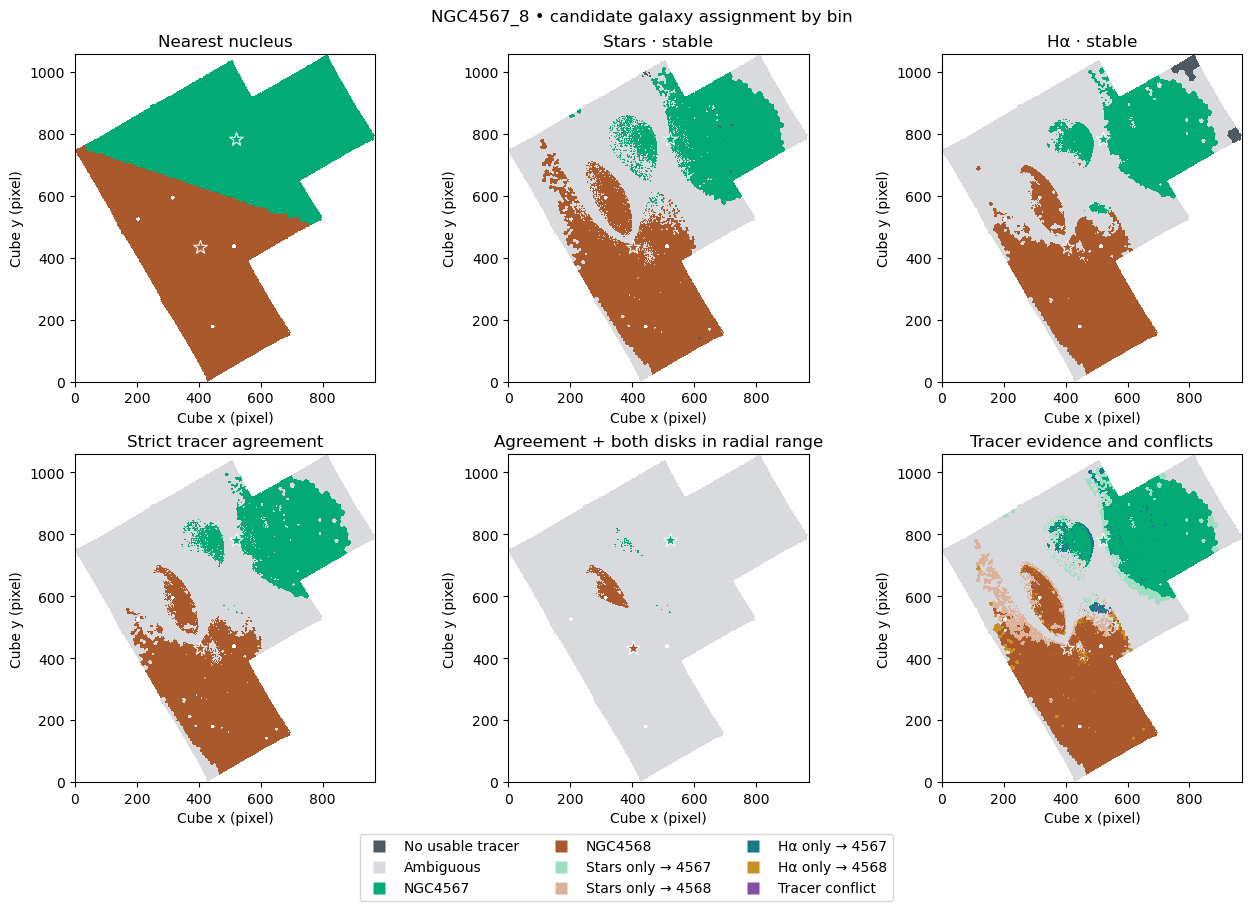

In [4]:
def to_image(values):
    image = np.full((ny, nx), np.nan)
    image[footprint] = values[inverse]
    return image

def map_panel(ax, image, title, **kwargs):
    im = ax.imshow(image, origin="lower", interpolation="nearest", rasterized=True, **kwargs)
    ax.set_title(title)
    ax.set_xlabel("Cube x (pixel)")
    ax.set_ylabel("Cube y (pixel)")
    for x, y, name in zip(cx, cy, GALAXIES):
        ax.scatter(x, y, marker="*", s=105, c=colours[name], edgecolor="white", linewidth=0.8)
    return im

def show_figure(fig):
    display(fig)
    plt.close(fig)

star_good, star_models = results["Stars", SEED_CUTS[0]]
ha_good, ha_models = results["Hα", SEED_CUTS[0]]
masked_star = np.where(star_good, star, np.nan)
masked_ha = np.where(ha_good, ha, np.nan)
vlim = np.nanpercentile(abs(np.r_[masked_star, masked_ha]), 99)
flux = spatial["FLUX"]
log_flux = np.log10(np.where(flux > 0, flux, np.nan))
fig, axes = plt.subplots(2, 3, figsize=(14, 9), layout="constrained")
im = map_panel(axes[0, 0], log_flux, "Continuum flux", cmap="gray_r")
fig.colorbar(im, ax=axes[0, 0], label="log₁₀ input flux")
for ax, values, title in [
    (axes[0, 1], masked_star, "Stellar velocity"), (axes[0, 2], masked_ha, "Hα velocity"),
    (axes[1, 0], star_models[0][0] - star_models[1][0], "Stellar model Δv (4567 − 4568)"),
    (axes[1, 1], ha_models[0][0] - ha_models[1][0], "Hα model Δv (4567 − 4568)"),
]:
    im = map_panel(ax, to_image(values), title, cmap="RdBu_r", vmin=-vlim, vmax=vlim)
    fig.colorbar(im, ax=ax, label="km s⁻¹", extend="both")
delta = masked_ha - masked_star
lim = np.nanpercentile(abs(delta), 98)
im = map_panel(axes[1, 2], to_image(delta), "Observed Hα − stars", cmap="PuOr_r", vmin=-lim, vmax=lim)
fig.colorbar(im, ax=axes[1, 2], label="km s⁻¹", extend="both")
fig.suptitle("NGC4567_8 • measured velocities and disk predictions")
show_figure(fig)

palette = ["#4f5962", "#d9dadd", colours[GALAXIES[0]], colours[GALAXIES[1]],
           "#9edfc4", "#dcb29a", "#157a85", "#c69026", "#804fa3"]
classes = ["No usable tracer", "Ambiguous", "NGC4567", "NGC4568",
           "Stars only → 4567", "Stars only → 4568", "Hα only → 4567",
           "Hα only → 4568", "Tracer conflict"]
cmap = ListedColormap(palette)
norm = BoundaryNorm(np.arange(-1.5, 8, 1), cmap.N)
fig, axes = plt.subplots(2, 3, figsize=(13, 9), layout="constrained")
for ax, values, title in zip(axes.flat,
    [nearest, s, g, consensus, np.where((consensus > 0) & ~both_radial, 0, consensus), detail],
    ["Nearest nucleus", "Stars · stable", "Hα · stable", "Strict tracer agreement",
     "Agreement + both disks in radial range", "Tracer evidence and conflicts"]):
    map_panel(ax, to_image(values), title, cmap=cmap, norm=norm)
legend = [Line2D([], [], marker="s", linestyle="none", markeredgecolor="none",
                 color=c, markersize=9, label=label) for c, label in zip(palette, classes)]
fig.suptitle("NGC4567_8 • candidate galaxy assignment by bin")
fig.legend(handles=legend, loc="outside lower center", ncol=3)
show_figure(fig)

## Which galaxy does a bin in the interface resemble?

Here the interface is the **projected strip** (0.40le tle0.60) between the nuclei, measured along the line joining them. This is a geometric region for inspection. It can include sightlines outside the physical interaction and can miss interacting material beyond the strip.

For each bin in the strip, evaluate both galaxy models at **that same sky position**. For each tracer, calculate (q_j=|v_{
m obs}-v_j|/s_j), where (s_j) is the larger of the bin's formal velocity error and the held-out prediction scale for galaxy (j). The preferred galaxy needs (q_{
m best}le2), a lead (q_{
m other}-q_{
m best}ge1), and a predicted velocity separation of at least (sqrt{s_{4567}^2+s_{4568}^2}). The preferred disk must be within its fitted radial range. For an interface label here, **both tracers** must choose the **same galaxy in all three fits**, and **both disk predictions** must lie within their radial ranges in all those fits.

The table gives actual examples. The normalized separation maps show where the fiducial predictions are too close for a tracer to make a choice (values below one). Passing this separation check is one of several conditions. A label is evidence for which disk the fitted centroids resemble. Both galaxies may still contribute light along that sightline.

Interface: 2,457 bins
NGC4567: 2 bins, 45 spaxels
NGC4568: 461 bins, 3,795 spaxels
Ambiguous: 1,994 bins, 54,748 spaxels
No usable tracer: 0 bins, 0 spaxels
Bin 13137 (NGC4567) marked at (x, y) = (480.4, 569.9).
Bin 11634 (NGC4568) marked at (x, y) = (372.9, 600.5).
Bin 14022 (Ambiguous) marked at (x, y) = (458.4, 611.6).


,Interface label,Bin,Tracer,Observed,Model 4567,Model 4568,q 4567,q 4568,Normalized separation
0,NGC4567,13137,Stars,64.45,61.25,45.15,0.41,2.39,1.43
1,NGC4567,13137,Hα,65.42,60.14,43.61,0.45,2.02,1.04
2,NGC4568,11634,Stars,122.57,94.91,114.93,3.51,0.94,1.77
3,NGC4568,11634,Hα,122.80,91.76,116.53,2.65,0.58,1.55
4,Ambiguous,14022,Stars,66.22,71.27,60.13,0.64,0.75,0.99
5,Ambiguous,14022,Hα,82.12,69.94,59.12,1.04,2.13,0.68


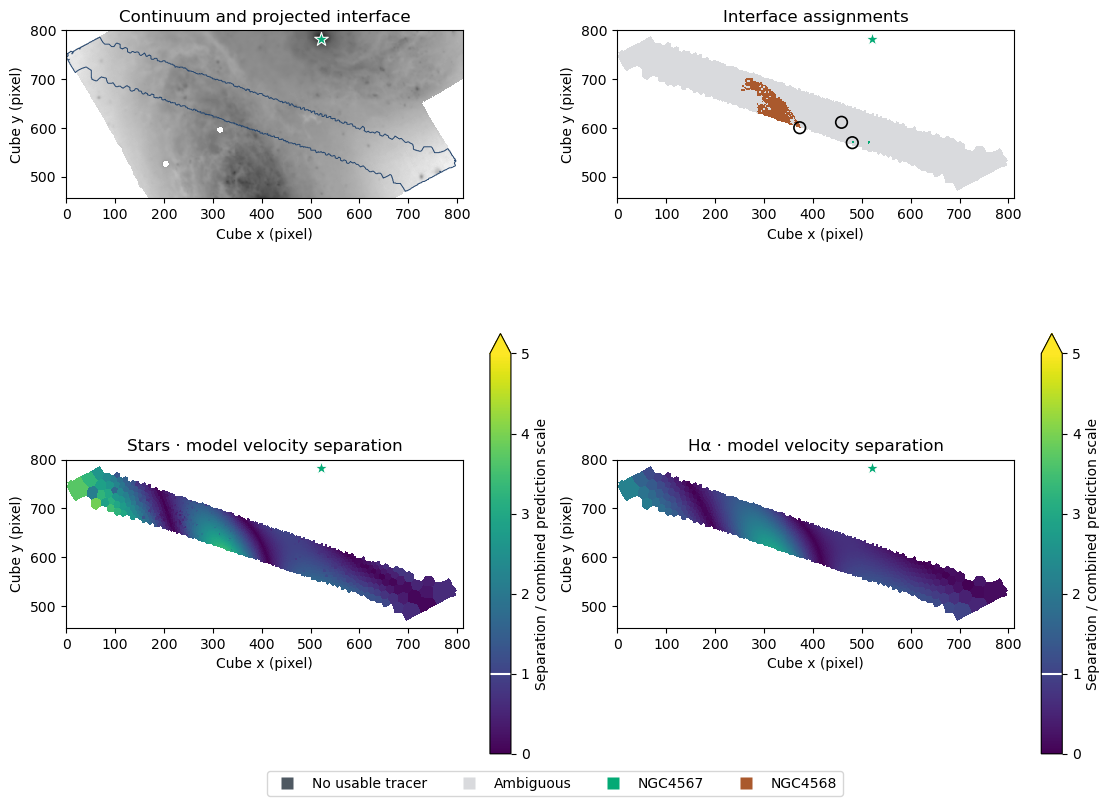

In [5]:
interface_label = np.where(both_radial & (consensus > 0), consensus, 0)
interface_label[(s < 0) & (g < 0)] = -1
n_interface = int(interface.sum())
print(f"Interface: {n_interface:,} bins")
for label, name in [(1, GALAXIES[0]), (2, GALAXIES[1]), (0, "Ambiguous"), (-1, "No usable tracer")]:
    take = interface & (interface_label == label)
    print(f"{name}: {take.sum():,} bins, {counts[take].sum():,} spaxels")

nominal = {}
for tracer, (vel, error, _) in tracers.items():
    usable, models = results[tracer, SEED_CUTS[0]]
    pred = np.array([model[0] for model in models])
    scale = np.maximum(error, np.array([model[1] for model in models])[:, None])
    separation_in_scale = abs(pred[0] - pred[1]) / np.hypot(*scale)
    nominal[tracer] = (pred, scale, np.where(usable, separation_in_scale, np.nan))

# Show one bin per outcome. Prefer examples near the midpoint; for the
# ambiguous example, look first where both tracers fail the separation test.
midpoint_distance = np.hypot(bx - cx.mean(), by - cy.mean())
examples = []
for label, name in [(1, GALAXIES[0]), (2, GALAXIES[1]), (0, "Ambiguous")]:
    candidates = interface & both_radial & (interface_label == label)
    if label == 0:
        close_predictions = (nominal["Stars"][2] < 1) & (nominal["Hα"][2] < 1)
        if np.any(candidates & close_predictions):
            candidates &= close_predictions
    if not np.any(candidates):
        continue
    i = np.argmin(np.where(candidates, midpoint_distance, np.inf))
    for tracer, (vel, _, _) in tracers.items():
        pred, scale, sep = nominal[tracer]
        q = abs(vel[i] - pred[:, i]) / scale[:, i]
        examples.append({"Interface label": name, "Bin": int(ids[i]), "Tracer": tracer,
                         "Observed": vel[i], "Model 4567": pred[0, i], "Model 4568": pred[1, i],
                         "q 4567": q[0], "q 4568": q[1], "Normalized separation": sep[i]})
    print(f"Bin {int(ids[i])} ({name}) marked at (x, y) = ({bx[i]:.1f}, {by[i]:.1f}).")
with pd.option_context("display.max_columns", None):
    display(pd.DataFrame(examples).round(2))

strip = to_image(interface.astype(float)) == 1
iy, ix = np.nonzero(strip)
xlim = (max(-0.5, ix.min() - 15), min(nx - 0.5, ix.max() + 15))
ylim = (max(-0.5, iy.min() - 15), min(ny - 0.5, iy.max() + 15))
fig, axes = plt.subplots(2, 2, figsize=(11, 9), layout="constrained")
map_panel(axes[0, 0], log_flux, "Continuum and projected interface", cmap="gray_r")
axes[0, 0].contour(strip, levels=[0.5], colors="#274870", linewidths=0.7)
map_panel(axes[0, 1], to_image(np.where(interface, interface_label, np.nan)),
          "Interface assignments", cmap=cmap, norm=norm)
for ax, tracer in zip(axes[1], tracers):
    values = np.where(interface, nominal[tracer][2], np.nan)
    im = map_panel(ax, to_image(values), f"{tracer} · model velocity separation",
                   cmap="viridis", vmin=0, vmax=5)
    cb = fig.colorbar(im, ax=ax, label="Separation / combined prediction scale", extend="max")
    cb.ax.axhline(1, color="white", linewidth=1.5)
for bin_id in dict.fromkeys(row["Bin"] for row in examples):
    i = np.searchsorted(ids, bin_id)
    axes[0, 1].scatter(bx[i], by[i], s=70, facecolors="none", edgecolors="black", linewidths=1.2)
for ax in axes.flat:
    ax.set(xlim=xlim, ylim=ylim)
fig.legend(handles=legend[:4], loc="outside lower center", ncol=4)
show_figure(fig)

## Is there a velocity gap across the interface?

Histograms show measured centroids in the projected strip. Candidate labels are stacked with the ambiguous bins, using one entry per bin and tracer. The count of empty 10 km/s intervals uses only intervals entirely inside the 5th–95th percentile range, so it tests for a broad gap in the main body of the distribution. The model gap is evaluated at each bin separately. Single-centroid products cannot show whether two velocity peaks coexist in one spectrum.

Both fiducial velocity gaps clear their tracer thresholds in 1,085 / 2,457 interface bins with both tracers usable.
Stars: measured central 90% spans 30.8 to 152.8 km/s; 0 of 11 interior 10 km/s intervals are empty. Median local model gap: 12.0 km/s.
Hα: measured central 90% spans 27.1 to 162.5 km/s; 0 of 13 interior 10 km/s intervals are empty. Median local model gap: 15.2 km/s.


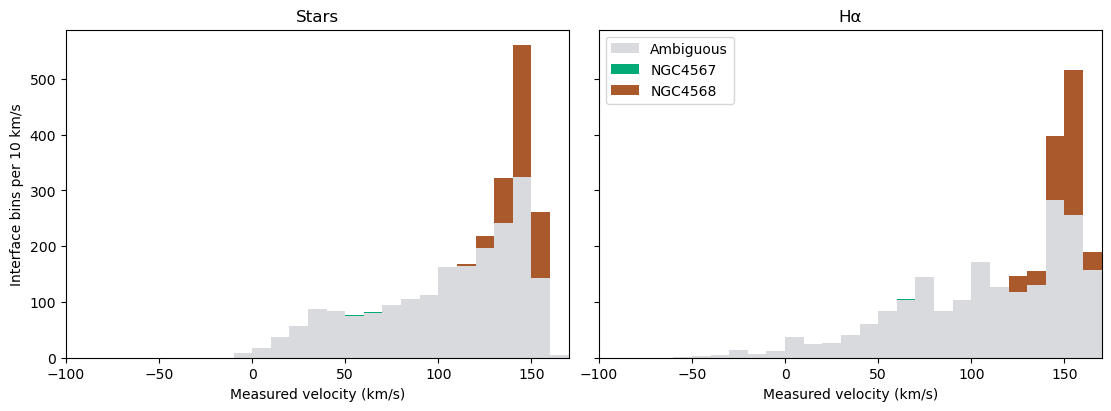

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained", sharey=True)
both_usable = interface & np.isfinite(nominal["Stars"][2]) & np.isfinite(nominal["Hα"][2])
both_separated = both_usable & (nominal["Stars"][2] >= 1) & (nominal["Hα"][2] >= 1)
print(f"Both fiducial velocity gaps clear their tracer thresholds in "
      f"{both_separated.sum():,} / {both_usable.sum():,} interface bins with both tracers usable.")
edges = np.arange(-160, 231, 10)
for ax, (tracer, (vel, _, _)) in zip(axes, tracers.items()):
    usable, models = results[tracer, SEED_CUTS[0]]
    use = interface & usable
    velocities = [vel[use & (interface_label == label)] for label in (0, 1, 2)]
    ax.hist(velocities, bins=edges, stacked=True, color=palette[1:4],
            label=["Ambiguous", *GALAXIES])
    low, high = np.percentile(vel[use], [5, 95])
    hist, _ = np.histogram(vel[use], bins=edges)
    central = (edges[:-1] >= low) & (edges[1:] <= high)
    assert np.any(central)
    gap = abs(models[0][0] - models[1][0])[use]
    print(f"{tracer}: measured central 90% spans {low:.1f} to {high:.1f} km/s; "
          f"{(hist[central] == 0).sum()} of {central.sum()} interior 10 km/s intervals are empty. "
          f"Median local model gap: {np.median(gap):.1f} km/s.")
    ax.set(title=tracer, xlabel="Measured velocity (km/s)", xlim=(-100, 170))
axes[0].set_ylabel("Interface bins per 10 km/s")
axes[1].legend()
show_figure(fig)

## How to use the maps

- In the interface, use the labels that also pass the two-disk radial support check as candidate assignments. Keep ambiguous bins as a separate category in any galaxy-specific measurement. The full-field maps give context for the velocity predictions.
- Inspect large coherent gas–star offsets and ambiguous or conflicting bins before interpreting component-specific quantities. The tracer comparison uses different spectral features from the same cube and common spatial bins, so its agreement is a consistency check.
- For a better disk prior, fit the outer continuum isophotes jointly with the velocity fields, or use a tilted-ring model with independently measured orientation and kinematic centres. Validate on held-out regions on the companion-facing side wherever morphology gives credible labels.
- For a flux split in the overlap, inspect the original spectra where the two model velocities are well separated. Compare one- and two-component fits to Hα+[N II] with a measured line-spread function and mock injection/recovery tests. Permit a disturbed-gas component if the residuals warrant it. The stellar equivalent is a two-LOSVD fit constrained by continuum S/N and recoverability. Where the components cannot be resolved, preserve an overlap region for separate reporting.

## Final two-galaxy assignment

Use `final_spaxel_label` for the complete split of the fitted footprint.
Values 1 and 2 mean NGC4567 and NGC4568, respectively. Value 0 marks pixels
outside the fitted footprint. Each spatial bin receives a single label,
which all its spaxels inherit.

Use the kinematic label where stars and Hα agree across all training-region
choices and both disks are within their fitted radial ranges. Otherwise use
the nearer nucleus in projected sky distance from the bin centroid. An
exact distance tie goes to NGC4567. This rule assigns the whole footprint,
including the projected interface. `final_kinematic_spaxel` marks the
assignments supported by the kinematic criteria. The remaining labels
are geometric allocations for a two-way partition.

,Region,Galaxy,Assigned spaxels,Kinematically supported,Nearest-nucleus fallback,Changed from nearest nucleus
0,Full footprint,NGC4567,261636,803,260833,99
1,Full footprint,NGC4568,248482,6693,241789,1324
2,Projected strip,NGC4567,28102,45,28057,45
3,Projected strip,NGC4568,30486,3795,26691,1324


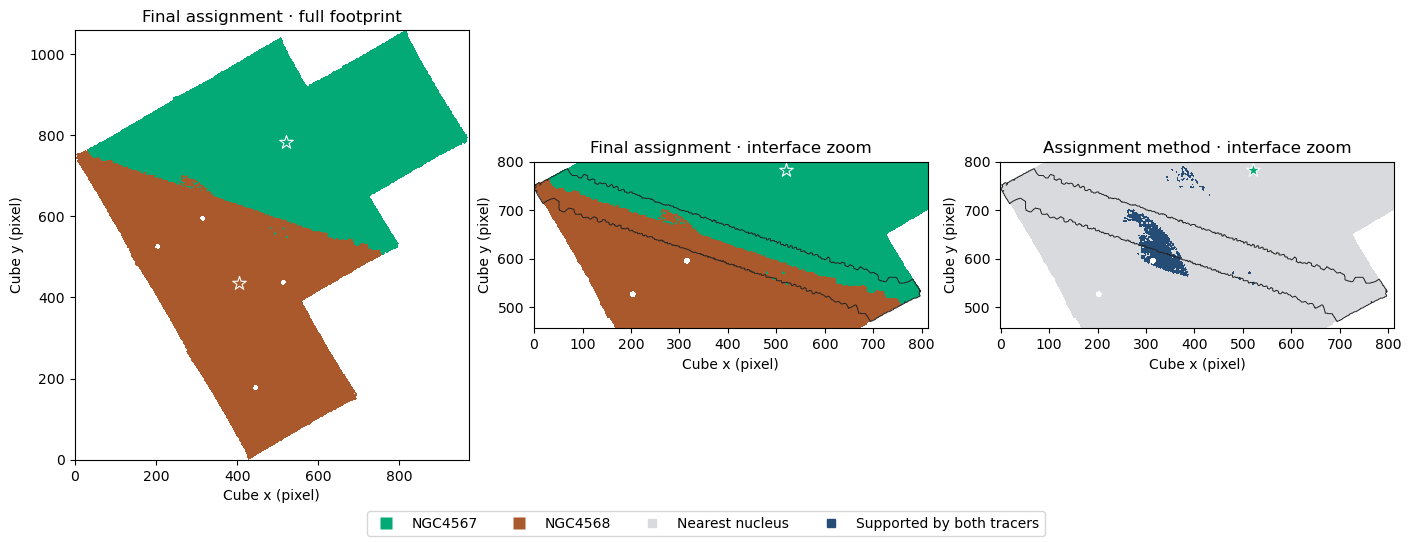

In [7]:
supported_kinematics = both_radial & (consensus > 0)
final_bin_label = np.where(supported_kinematics, consensus, nearest)
final_spaxel_label = np.zeros(footprint.shape, dtype=np.uint8)
final_spaxel_label[footprint] = final_bin_label[inverse]
final_kinematic_spaxel = np.zeros_like(footprint)
final_kinematic_spaxel[footprint] = supported_kinematics[inverse]
assert np.all(np.isin(final_spaxel_label[footprint], [1, 2]))
assert np.array_equal(final_spaxel_label > 0, footprint)

rows = []
for region, selected in [("Full footprint", np.ones_like(interface)), ("Projected strip", interface)]:
    for label, name in enumerate(GALAXIES, start=1):
        assigned = selected & (final_bin_label == label)
        rows.append({
            "Region": region,
            "Galaxy": name,
            "Assigned spaxels": counts[assigned].sum(),
            "Kinematically supported": counts[assigned & supported_kinematics].sum(),
            "Nearest-nucleus fallback": counts[assigned & ~supported_kinematics].sum(),
            "Changed from nearest nucleus": counts[assigned & (nearest != label)].sum(),
        })
with pd.option_context("display.max_columns", None):
    display(pd.DataFrame(rows))

fig, axes = plt.subplots(1, 3, figsize=(14, 5.5), layout="constrained")
final_image = np.where(footprint, final_spaxel_label, np.nan)
map_panel(axes[0], final_image, "Final assignment · full footprint", cmap=cmap, norm=norm)
map_panel(axes[1], final_image, "Final assignment · interface zoom", cmap=cmap, norm=norm)
method_cmap = ListedColormap(["#d9dadd", "#254d75"])
method_image = np.where(footprint, final_kinematic_spaxel.astype(float), np.nan)
map_panel(axes[2], method_image, "Assignment method · interface zoom",
          cmap=method_cmap, vmin=0, vmax=1)
for ax in axes[1:]:
    ax.contour(strip, levels=[0.5], colors="#252525", linewidths=0.7)
    ax.set(xlim=xlim, ylim=ylim)
method_legend = [
    Line2D([], [], marker="s", linestyle="none", color=color, label=label)
    for color, label in zip(method_cmap.colors, ["Nearest nucleus", "Supported by both tracers"])
]
fig.legend(handles=legend[2:4] + method_legend, loc="outside lower center", ncol=4)
show_figure(fig)

## Final assignment with stellar post-fit S/N > 25

Apply a strict quality cut using `SNR_POSTFIT` from the stellar KIN maps
after assigning the galaxies. This keeps the same boundary and selects
bins whose stellar fit passes the cut. The models and labels are fixed.
`final_spaxel_label_snr25` has values 1 and 2 for retained galaxy
assignments and 0 for excluded pixels. Grey within the footprint marks
spaxels removed by the S/N cut.

,Region,Galaxy,Before cut,S/N > 25,Retained (%),Retained with kinematic support
0,Full footprint,NGC4567,261636,218029,83.3,803
1,Full footprint,NGC4568,248482,217113,87.4,6693
2,Projected strip,NGC4567,28102,20884,74.3,45
3,Projected strip,NGC4568,30486,22647,74.3,3795


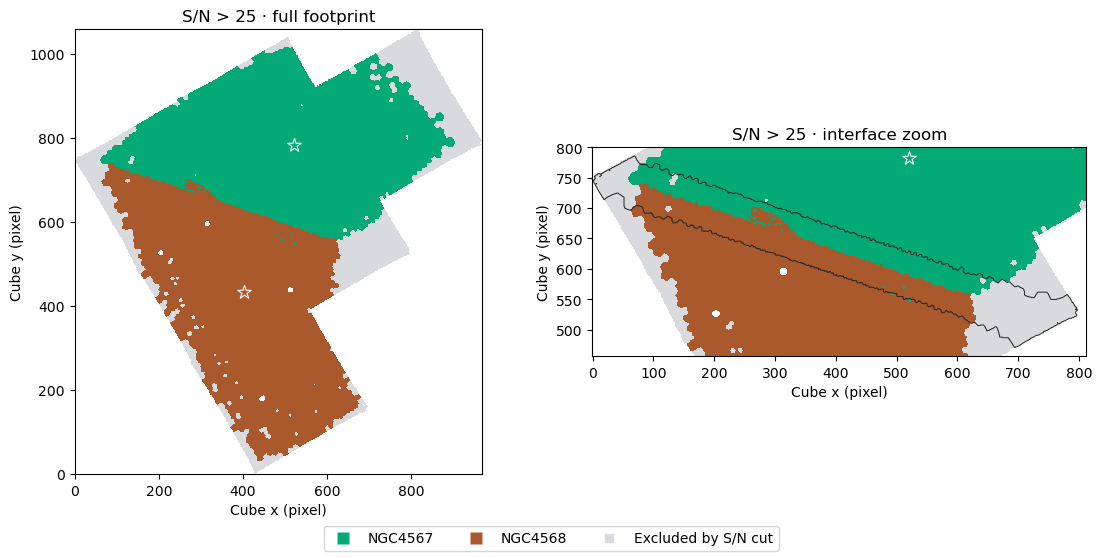

In [8]:
snr_maps, snr_grids = read_maps("kin_maps", ["SNR_POSTFIT"])
assert snr_maps["SNR_POSTFIT"].shape == footprint.shape
snr_sky = snr_grids["SNR_POSTFIT"].pixel_to_world(grid_x, grid_y)
assert np.max(sky_check.separation(snr_sky).arcsec) < 1e-4
postfit_snr = per_bin(snr_maps["SNR_POSTFIT"])
passes_snr25 = np.isfinite(postfit_snr) & (postfit_snr > 25)
retained_spaxel = np.zeros_like(footprint)
retained_spaxel[footprint] = passes_snr25[inverse]
final_spaxel_label_snr25 = np.where(retained_spaxel, final_spaxel_label, 0)
assert np.array_equal(final_spaxel_label_snr25 > 0, retained_spaxel)
assert np.all(np.isin(final_spaxel_label_snr25[retained_spaxel], [1, 2]))
assert retained_spaxel.sum() == counts[passes_snr25].sum()

rows = []
for region, selected in [("Full footprint", np.ones_like(interface)), ("Projected strip", interface)]:
    for label, name in enumerate(GALAXIES, start=1):
        assigned = selected & (final_bin_label == label)
        retained = assigned & passes_snr25
        before = counts[assigned].sum()
        after = counts[retained].sum()
        rows.append({"Region": region, "Galaxy": name, "Before cut": before,
                     "S/N > 25": after, "Retained (%)": 100 * after / before,
                     "Retained with kinematic support": counts[retained & supported_kinematics].sum()})
with pd.option_context("display.max_columns", None):
    display(pd.DataFrame(rows).round(1))

cut_image = np.where(footprint, final_spaxel_label_snr25, np.nan)
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), layout="constrained")
map_panel(axes[0], cut_image, "S/N > 25 · full footprint", cmap=cmap, norm=norm)
map_panel(axes[1], cut_image, "S/N > 25 · interface zoom", cmap=cmap, norm=norm)
axes[1].contour(strip, levels=[0.5], colors="#252525", linewidths=0.7)
axes[1].set(xlim=xlim, ylim=ylim)
excluded = Line2D([], [], marker="s", linestyle="none", color=palette[1],
                  label="Excluded by S/N cut")
fig.legend(handles=legend[2:4] + [excluded], loc="outside lower center", ncol=3)
show_figure(fig)

## R-band isophotes first, kinematics where the light is uncertain

Fit the sum of two elliptical Sérsic profiles to `R_FLUX` in the VRI image.
Each profile has a fixed catalogue nucleus and fitted effective surface
brightness, effective radius, Sérsic index, axis ratio, and position angle.
Use the existing three training-strip choices, excluding the inner 3 arcsec
of either nucleus. Fit in log flux with a robust loss so bright knots do
not control the fit. A spatial block holdout checks the fit away from the
excluded strip. The overlap predictions remain extrapolations from this fit.
The smooth ellipses approximate the continuum light and can miss spiral arms,
dust lanes, and tidal structure. [Peng et al. (2002)](https://arxiv.org/abs/astro-ph/0204182)

Sum the predicted component fluxes over each kinematic bin. R band decides
where the same component is at least twice as bright in all three fits
and the fiducial summed light matches the observed bin flux to within a
factor of two. Elsewhere, test the existing stable stellar plus Hα label
with both disks inside their fitted radial ranges. If that also gives no
label, use the brighter fiducial R-band component as a low-confidence
allocation. This gives a complete split and a separate map of the rule used.
The R-band uncertainty region is defined by these model checks and can
extend beyond the original geometric inspection strip.

In [9]:
from scipy.special import gammaincinv

vri_path = ROOT.parent / "v3tk_to_VRI" / f"{CUBE}_DATACUBE_FINAL_WCS_Pall_mad_red_v3tk_VRI.fits"
with fits.open(vri_path) as hdus:
    r_hdu = hdus["R_FLUX"]
    r_flux = r_hdu.data.astype(float)
    r_wcs = WCS(r_hdu.header).celestial
    r_unit = r_hdu.header["BUNIT"]
assert r_flux.shape == footprint.shape
assert np.max(sky_check.separation(r_wcs.pixel_to_world(grid_x, grid_y)).arcsec) < 1e-4

r_sky = r_wcs.pixel_to_world(px, py)
r_offsets = []
for centre in centres:
    local_sky = r_sky.transform_to(centre.skyoffset_frame())
    r_offsets.append((local_sky.lon.wrap_at("180d").arcsec, local_sky.lat.arcsec))
reast, rnorth = r_offsets[0]
rt = (axis[0] * reast + axis[1] * rnorth) / separation**2
r_core_ok = np.minimum(*(np.hypot(east, north) for east, north in r_offsets)) > CORE_EXCLUSION
r_observed = r_flux[footprint]
r_observed_ok = np.isfinite(r_observed) & (r_observed > 0)
r_sample = r_observed_ok & r_core_ok & (px % 6 == 0) & (py % 6 == 0)
r_holdout = ((px // 30 + 2 * (py // 30)) % 5) == 0

def sersic_pair(parameters, coordinates):
    fluxes = []
    for (log_ie, re, n, q, pa), (east, north) in zip(parameters.reshape(2, 5), coordinates):
        major = east * np.sin(pa) + north * np.cos(pa)
        minor = east * np.cos(pa) - north * np.sin(pa)
        radius = np.hypot(major, minor / q)
        bn = gammaincinv(2 * n, 0.5)
        fluxes.append(np.exp(log_ie - bn * ((radius / re)**(1 / n) - 1)))
    return np.array(fluxes)

r_fits = []
r_check = []
r_bin_models = []
r_bounds = ([-12, 5, 0.5, 0.2, -2*np.pi] * 2, [1, 200, 6, 1, 2*np.pi] * 2)
for cut in SEED_CUTS:
    fit_region = r_sample & ((rt < 1 - cut) | (rt > cut))
    train, test = fit_region & ~r_holdout, fit_region & r_holdout
    train_coords = [(e[train], n[train]) for e, n in r_offsets]
    target = np.log(r_observed[train])

    def r_residual(params):
        return np.log(sersic_pair(params, train_coords).sum(axis=0)) - target

    trials = []
    for pa0, pa1 in [(0, 0), (np.pi/2, 0), (0, np.pi/2), (np.pi/2, np.pi/2)]:
        start = [-2.5, 40, 1.5, 0.65, pa0, -2.5, 50, 1.5, 0.4, pa1]
        trials.append(least_squares(r_residual, start, bounds=r_bounds,
                                   loss="soft_l1", f_scale=0.25, x_scale="jac"))
    best = min((trial for trial in trials if trial.success), key=lambda trial: trial.cost)
    r_fits.append(best.x)
    test_model = sersic_pair(best.x, [(e[test], n[test]) for e, n in r_offsets])
    heldout_abs = abs(np.log10(test_model.sum(axis=0) / r_observed[test]))
    r_check.append({"Seed cut": cut, "Train samples": train.sum(), "Holdout samples": test.sum(),
                    "Holdout median |log10 residual|": np.median(heldout_abs),
                    "Holdout P90 |log10 residual|": np.quantile(heldout_abs, 0.9),
                    "Parameters at bounds": np.count_nonzero(best.active_mask)})
    model_pixels = sersic_pair(best.x, r_offsets)
    r_bin_models.append(np.array([np.bincount(inverse, weights=values) for values in model_pixels]))
r_bin_models = np.array(r_bin_models)
r_nominal_pixels = sersic_pair(r_fits[0], r_offsets)
r_logratio = np.log10(r_bin_models[:, 0] / r_bin_models[:, 1])
assert np.isfinite(r_logratio).all()
r_bin_observed = np.bincount(inverse, weights=np.where(np.isfinite(r_observed), r_observed, 0))
r_total_agreement = r_bin_observed / r_bin_models[0].sum(axis=0)
r_good_total = (r_total_agreement >= 0.5) & (r_total_agreement <= 2)
r_threshold = np.log10(2)
r_decisive = np.select(
    [r_good_total & np.all(r_logratio >= r_threshold, axis=0),
     r_good_total & np.all(r_logratio <= -r_threshold, axis=0)], [1, 2]
)
r_use_kinematics = (r_decisive == 0) & supported_kinematics
r_nominal_label = np.where(r_logratio[0] >= 0, 1, 2)
rband_bin_label = np.where(r_decisive > 0, r_decisive, np.where(r_use_kinematics, consensus, r_nominal_label))
r_assignment_rule = np.select([r_decisive > 0, r_use_kinematics], [1, 2], default=3)
rband_spaxel_label = np.zeros(footprint.shape, dtype=np.uint8)
rband_spaxel_label[footprint] = rband_bin_label[inverse]
rband_spaxel_label_snr25 = np.where(retained_spaxel, rband_spaxel_label, 0)
assert np.array_equal(rband_spaxel_label > 0, footprint)
assert np.array_equal(rband_spaxel_label_snr25 > 0, retained_spaxel)
assert np.all(np.isin(rband_spaxel_label[footprint], [1, 2]))

display(pd.DataFrame(r_check).round(3))
display(pd.DataFrame({
    "Galaxy": GALAXIES,
    "I_e": np.exp(r_fits[0][::5]),
    "R_e (arcsec)": r_fits[0][1::5],
    "Sérsic n": r_fits[0][2::5],
    "Axis ratio": r_fits[0][3::5],
    "PA (deg E of N)": np.rad2deg(r_fits[0][4::5]) % 180,
}).round(3))

,Seed cut,Train samples,Holdout samples,Holdout median |log10 residual|,Holdout P90 |log10 residual|,Parameters at bounds
0,0.60,10027,2506,0.052,0.131,0
1,0.45,11302,2828,0.051,0.132,0
2,0.70,8852,2220,0.051,0.127,0


,Galaxy,I_e,R_e (arcsec),Sérsic n,Axis ratio,PA (deg E of N)
0,NGC4567,0.110,45.276,0.860,0.677,83.392
1,NGC4568,0.157,53.700,1.187,0.393,27.068


Strong R-band labels disagree with supported kinematics in 0 spaxels.


,Selection,Galaxy,Total spaxels,Strong R-band dominance,Kinematics where R band is uncertain,Weak R-band fallback,Changed from previous split
0,Full footprint,NGC4567,243114,213667,99,29348,11254
1,Full footprint,NGC4568,267004,216000,267,50737,29776
2,Projected strip,NGC4567,23547,13972,45,9530,9238
3,Projected strip,NGC4568,35041,12910,267,21864,13793
4,Full footprint · S/N > 25,NGC4567,195347,170066,99,25182,4407
5,Full footprint · S/N > 25,NGC4568,239795,200076,267,39452,27089
6,Projected strip · S/N > 25,NGC4567,12411,5038,45,7328,3972
7,Projected strip · S/N > 25,NGC4568,31120,12910,267,17943,12445


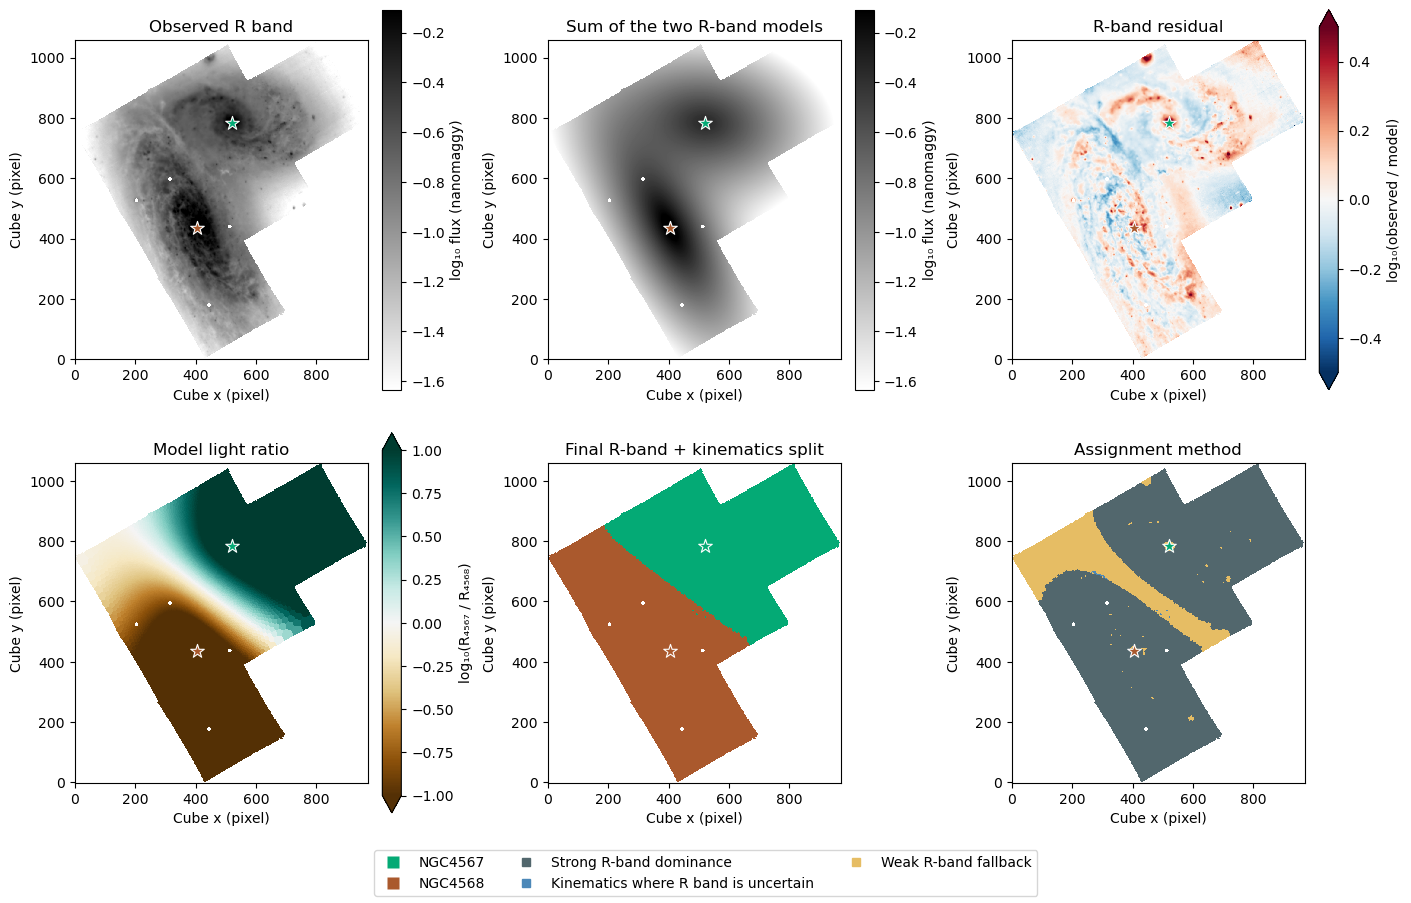

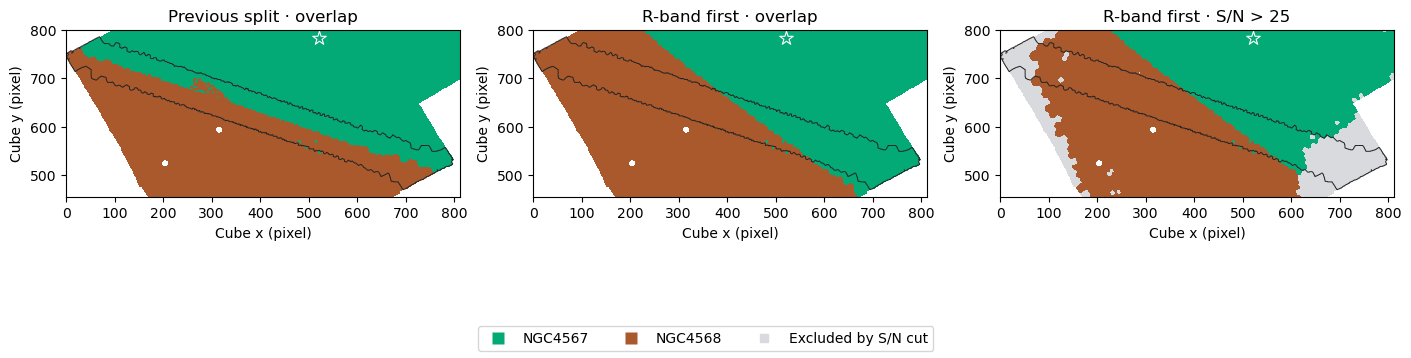

In [10]:
r_rule_names = ["Strong R-band dominance", "Kinematics where R band is uncertain", "Weak R-band fallback"]
summary = []
for selection, mask in [
    ("Full footprint", np.ones_like(interface)),
    ("Projected strip", interface),
    ("Full footprint · S/N > 25", passes_snr25),
    ("Projected strip · S/N > 25", interface & passes_snr25),
]:
    for label, galaxy in enumerate(GALAXIES, start=1):
        chosen = mask & (rband_bin_label == label)
        row = {"Selection": selection, "Galaxy": galaxy, "Total spaxels": counts[chosen].sum()}
        for method, name in enumerate(r_rule_names, start=1):
            row[name] = counts[chosen & (r_assignment_rule == method)].sum()
        row["Changed from previous split"] = counts[chosen & (final_bin_label != label)].sum()
        summary.append(row)
with pd.option_context("display.max_columns", None):
    display(pd.DataFrame(summary))
r_conflict = (r_decisive > 0) & supported_kinematics & (r_decisive != consensus)
print(f"Strong R-band labels disagree with supported kinematics in {counts[r_conflict].sum():,} spaxels.")

r_component_sum = np.full(footprint.shape, np.nan)
r_component_sum[footprint] = r_nominal_pixels.sum(axis=0)
r_log_image = np.log10(np.where(footprint & (r_flux > 0), r_flux, np.nan))
r_log_model = np.log10(r_component_sum)
rmin, rmax = np.nanpercentile(r_log_image, [2, 99])
fig, ax = plt.subplots(2, 3, figsize=(14, 9), layout="constrained")
for panel, values, title in [(ax[0, 0], r_log_image, "Observed R band"),
                             (ax[0, 1], r_log_model, "Sum of the two R-band models")]:
    im = map_panel(panel, values, title, cmap="gray_r", vmin=rmin, vmax=rmax)
    fig.colorbar(im, ax=panel, label=f"log₁₀ flux ({r_unit})")
im = map_panel(ax[0, 2], r_log_image - r_log_model, "R-band residual", cmap="RdBu_r", vmin=-0.5, vmax=0.5)
fig.colorbar(im, ax=ax[0, 2], label="log₁₀(observed / model)", extend="both")
im = map_panel(ax[1, 0], to_image(r_logratio[0]), "Model light ratio", cmap="BrBG", vmin=-1, vmax=1)
fig.colorbar(im, ax=ax[1, 0], label="log₁₀(R₄₅₆₇ / R₄₅₆₈)", extend="both")
map_panel(ax[1, 1], to_image(rband_bin_label), "Final R-band + kinematics split", cmap=cmap, norm=norm)
r_rule_cmap = ListedColormap(["#52676d", "#4c88b8", "#e6bd64"])
map_panel(ax[1, 2], to_image(r_assignment_rule), "Assignment method",
          cmap=r_rule_cmap, vmin=0.5, vmax=3.5)
rule_legend = [Line2D([], [], marker="s", linestyle="none", color=color, label=name)
               for color, name in zip(r_rule_cmap.colors, r_rule_names)]
fig.legend(handles=legend[2:4] + rule_legend, loc="outside lower center", ncol=3)
show_figure(fig)

fig, ax = plt.subplots(1, 3, figsize=(14, 4.5), layout="constrained")
map_panel(ax[0], to_image(final_bin_label), "Previous split · overlap", cmap=cmap, norm=norm)
map_panel(ax[1], to_image(rband_bin_label), "R-band first · overlap", cmap=cmap, norm=norm)
map_panel(ax[2], np.where(footprint, rband_spaxel_label_snr25, np.nan),
          "R-band first · S/N > 25", cmap=cmap, norm=norm)
for panel in ax:
    panel.contour(strip, levels=[0.5], colors="#252525", linewidths=0.7)
    panel.set(xlim=xlim, ylim=ylim)
fig.legend(handles=legend[2:4] + [excluded], loc="outside lower center", ncol=3)
show_figure(fig)